In [1]:
import random as rand
from matplotlib import pyplot as plt

# GGL generator

In [2]:
def ggl(state:int): 
    a = 16807
    m = pow(2, 31) - 1
    newState = (a*state) % m
    return newState

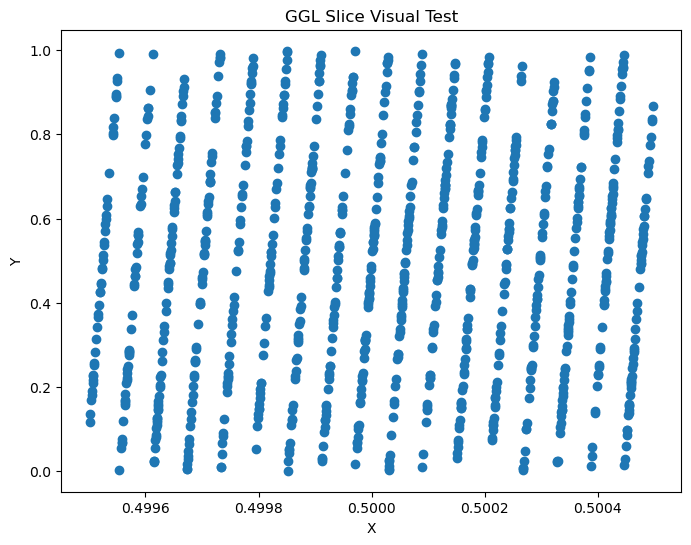

In [3]:
# Generate the pairs of sequences
i = 0
n = 1000000
m = pow(2, 31) - 1
state = 123456
xSeq = []
ySeq = []
while i < n:
    state = ggl(state)
    x = state/m
    state = ggl(state)
    i+= 1
    if (x < 0.5005) and (x > 0.4995):
        xSeq.append(x)
        ySeq.append(state/m)
        

# Plotting 
plt.figure(figsize=(8, 6))
plt.scatter(xSeq, ySeq)
plt.title("GGL Slice Visual Test")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

# RAN3 simulator

In [4]:
def ran3(stateSeq):
    m = pow(2,32)
    newState = (stateSeq[0] - stateSeq[31]) % m
    del stateSeq[0]
    stateSeq.append(newState)
    return newState

In [5]:
# Simulate a random sequence using ggl for seeding
state = 12345
stateSeq = []
for i in range(0,55):
    state = ggl(state)
    stateSeq.append(state)

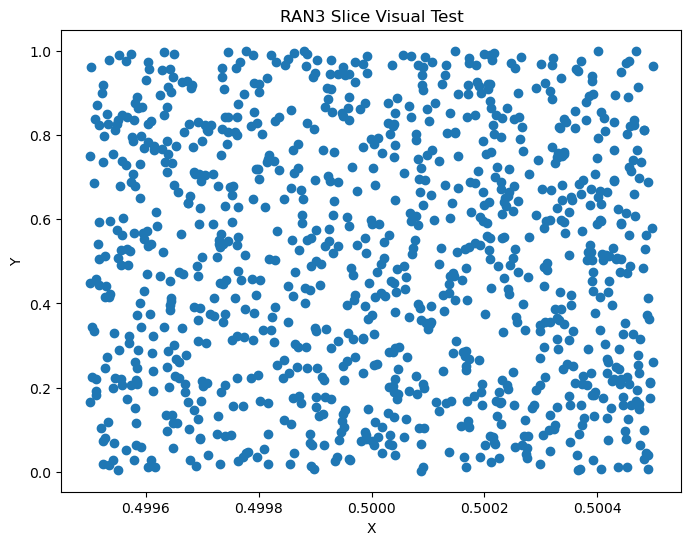

In [6]:
# Generate the pairs of sequences for RAN3
i = 0
n = 1000000
m = pow(2,32)
xSeq = []
ySeq = []
while i < n:
    state = ran3(stateSeq)
    x = state/m
    state = ran3(stateSeq)
    i+= 1
    if (x < 0.5005) & (x > 0.4995):
        xSeq.append(x)
        ySeq.append(state/m)
        
        
# Plotting 
plt.figure(figsize=(8, 6))
plt.scatter(xSeq, ySeq)
plt.title("RAN3 Slice Visual Test")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

# Mersenne-Twister simulator

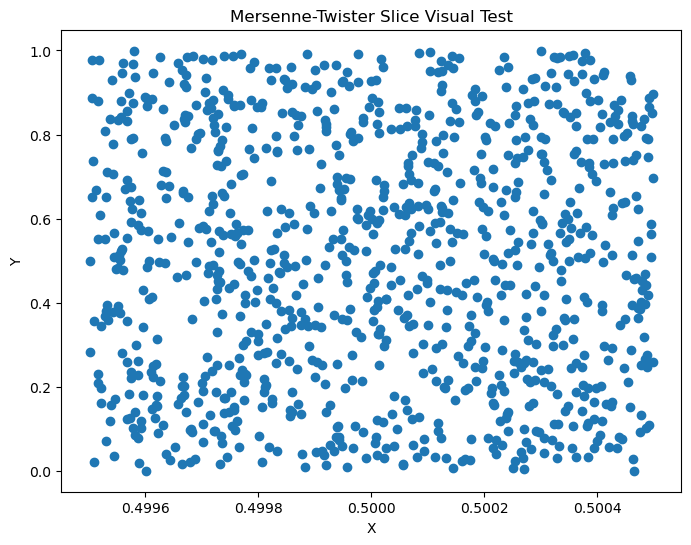

In [7]:
# Generate the pairs of sequences for  Mersenne-Twister simulator
i = 0
n = 1000000
state = 12345
xSeq = []
ySeq = []
while i < n:
    state = rand.random()
    x = state
    state = rand.random()
    i+= 1
    if (x < 0.5005) & (x > 0.4995):
        xSeq.append(x)
        ySeq.append(state)
        
        
# Plotting 
plt.figure(figsize=(8, 6))
plt.scatter(xSeq, ySeq)
plt.title("Mersenne-Twister Slice Visual Test")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

## Ggl sufferes from serial correlation, something that all LCG suffers from. Other generators like RAN3 (a lagged Fibonacci/shift-based algorithm) and Mersenne Twister eliminate this flaw and are much more pseudo-random.